# Problem 1: Rock–Paper–Scissors Classification
Loads the supplied Teachable Machine model and performs inference on a new image. The original `rock-paper-scissors.py` is unchanged. Run this notebook from this folder. Use the Python 3.11 environment described in START-HERE.txt. The supplied model is a legacy Keras model; the optional tf_keras import supports a separate newer TensorFlow environment with tf-keras installed.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
try:
    from tf_keras.models import load_model  # Optional legacy Keras package
except ModuleNotFoundError as exc:
    if exc.name != 'tf_keras':
        raise
    from keras.models import load_model

BASE = Path.cwd()
MODEL_PATH = BASE / 'model' / 'keras_model.h5'
LABEL_PATH = BASE / 'model' / 'labels.txt'
if not MODEL_PATH.exists():
    raise FileNotFoundError('Open this notebook with the assignment folder as the working directory.')
model = load_model(MODEL_PATH, compile=False)
class_names = [line.strip().split(' ', 1)[1] for line in LABEL_PATH.read_text().splitlines() if line.strip()]
print('Input shape:', model.input_shape)
print('Classes:', class_names)
assert model.output_shape[-1] == len(class_names)

Input shape: (None, 224, 224, 3)
Classes: ['rock', 'paper', 'scissors']


In [2]:
def classify_image(image_path, show=True):
    image_path = Path(image_path)
    with Image.open(image_path) as source:
        image = source.convert('RGB')
    fitted = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    data = (np.asarray(fitted, dtype=np.float32) / 127.5 - 1.0)[None, ...]
    prediction = model.predict(data, verbose=0)[0]
    index = int(np.argmax(prediction))
    if show:
        plt.figure(figsize=(4, 4))
        plt.imshow(image)
        plt.title(f'{image_path.name}: {class_names[index]} ({prediction[index]:.2%})')
        plt.axis('off')
        plt.show()
    print(f'Image: {image_path.name}')
    print(f'Class: {class_names[index]}')
    print(f'Confidence Score: {prediction[index]:.6f}')
    return class_names[index], float(prediction[index])

## Accept a new image
Change `IMAGE_PATH` to any new photograph, then rerun the following cell.

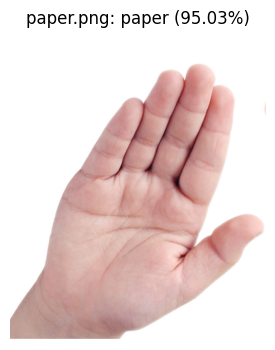

Image: paper.png
Class: paper
Confidence Score: 0.950250


In [3]:
IMAGE_PATH = BASE / 'paper.png'
result = classify_image(IMAGE_PATH)

## Test the three supplied examples
These are sample predictions, not an independent estimate of model accuracy.

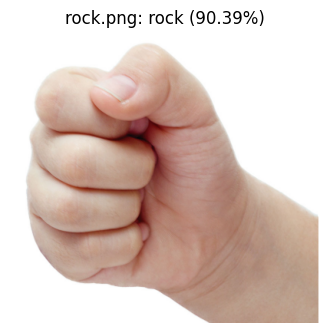

Image: rock.png
Class: rock
Confidence Score: 0.903869


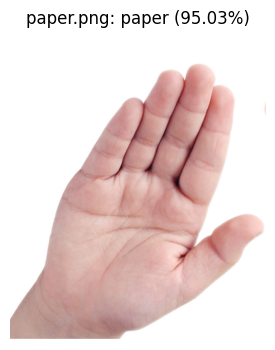

Image: paper.png
Class: paper
Confidence Score: 0.950250


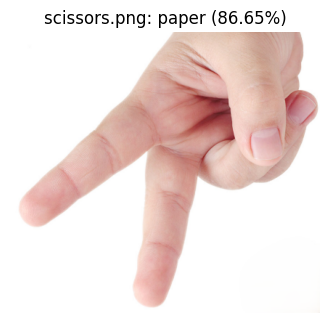

Image: scissors.png
Class: paper
Confidence Score: 0.866485


In [4]:
for filename in ['rock.png', 'paper.png', 'scissors.png']:
    classify_image(BASE / filename)

## New model verification
The updated Teachable Machine export was tested with the prescribed RGB, center-crop, and [-1, 1] preprocessing:

| Input | Predicted class | Confidence | Correct? |
|---|---|---|---|
| rock.png | rock | 90.39% | Yes |
| paper.png | paper | 95.03% | Yes |
| scissors.png | paper | 86.65% | No |

The model correctly classifies 2 of the 3 supplied samples. The scissors prediction remains incorrect. These three samples are not an independent generalization benchmark; confidence does not guarantee correctness. Add varied scissors examples in Teachable Machine and evaluate new, separate images before treating the classifier as reliable. The displayed prediction always comes from the model, not the filename.
